# 2D coarse graining of bedload transport

In this example, we demonstrate how to use the `CoarseGraining` to perform coarse graining on a 2D bedload transport simulation and plot the results.
In order to do that, you can use the `compute_CG.ipynb` Jupyter notebook provided in the `examples/bedload_transport` directory. 

The files required for this example can be found in the `examples/bedload_transport` directory of the repository:

- The DEM simualtion data files in the `examples/bedload_transport/DEM_data` directory
- The configuration file `config.ini` in the `examples/bedload_transport` directory

## Import packages

First, ensure you have the necessary libraries installed:

In [1]:
from pysammos.utils.config_loader import load_config
from pysammos.coarse_graining import CoarseGraining
from pysammos.data_write.h5.writer import H5XarrayManager
from pysammos.post_averaging.profiles import VerticalIntegrator

Hello from pysammos
Loading macroscopic_fields package...
Loading data_read package...
Loading particle_phase package...
Loading spatial_weights package...
Loading neighbour_search package...
Loading grid_generation package...
Loading data_handle package...
Loading data_write package...
Loading post_averaging package...


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pyvista as pv

## Completing the Configuration file

Before running the coarse graining, ensure that the `config.ini` file is properly set up. The configuration file contains various sections, marked by headers in square brackets. 

The `paths` section specifies the input and output file paths.

```ini
[paths]
particles_path = ./VTU/DES_FB1_
contacts_path = ./VTU/ENTIRE_DOMAIN_
output_path = ./PysammosCG/
```

The `timesteps` section defines the time range and interval for the coarse graining process. `t0` is the starting timestep, `tf` is the ending timestep, and `dt` is the timestep interval. 
Note that the `t_pad` parameter is used to specify the number of zero-padding to be added to the `t0` and `tf` values when reading the DEM simulation data files. This is useful when the timestep numbers in the filenames have leading zeros.

```ini
[timesteps]
t0 = 150
tf = 152
dt = 1 
t_pad = 4
```


The `smoothing_function` section defines the `type` of smoothing function to be used for coarse graining. In this case, we are using the Lucy function.
Find the corresponding documentation in the page `kernels_module`.

```ini
[smoothing_function]
type = Lucy
```

The `flags` section defines the `partialignore` flag, which indicates whether to ignore particle phases during the coarse graining process. 
It will force the number phases to be one if it is set to True.

```ini
[flags]
partialignore = True
```

The `key_mapping` section maps the DEM simulation data fields to the expected keys used in the coarse graining process.

```ini
[key_mapping]
Global_ID = Particle_ID
Particle_Velocity = Velocity
Particle_Diameter = Diameter
Particle_Density = Density
Particle_Volume = Volume
Particle_Mass = Mass
Particle_Radius = None
Coordination_Number = None
Particle_i_ID = Particle_ID_1
Particle_j_ID = Particle_ID_2
Force_ij = FORCE_CHAIN_FC
Contact_ij = FORCE_CHAIN_CONTACT_POINT
```

The `DEM_software` section specifies the DEM software used for the simulation. In this case, it is set to `mfix`.

```ini
[DEM_software]
software = mfix
```

The `grid_info` section specifies the grid parameters for the coarse graining process, including the grid dimensions, axes, and boundaries. 

- The `grid_dimension` is set to '2' for a 2D simulation.
- The `grid_axes` are set to '`xy`', indicating that the coarse graining will be performed in the x and y directions.
- The `automatic_grid` is set to `False`, allowing for manual specification of grid boundaries.
- The `x_min`, `x_max`, `y_min`, and `y_max` parameters define the spatial extent of the grid.
- The `z_transect` is set to '0.0', indicating that the coarse graining will be performed at this z-level.
- The `x_axis_periodic` is set to '`True`', indicating that the x-axis is periodic, while the y and z axes are non-periodic.

Find the corresponding documentation in the following page: `grid_generation`.

```ini
[grid_info]
grid_dimension = 2
grid_axes = xy
automatic_grid = False
x_min = 0.00105
x_max = 0.5
y_min = 0.001
y_max = 0.24
z_min = None
z_max = None
x_transect = None
y_transect = None
z_transect = 0.0
x_axis_periodic = True
y_axis_periodic = False
z_axis_periodic = False
```

The `simulation_box` section specifies the limits of the DEM simulation box, required on every periodic axis in `[grid_info]`

```ini
[simulation_box]
x_range = 0, 0.5
y_range = None
z_range = None
```

The `fields_to_export` section specifies which coarse-grained fields to export. 

```ini
[fields_to_export]
volume_fraction = True
density_particle = False
density_mixture = True
momentum_density = False
velocity = True
velocity_gradient = True
kinetic_tensor = False
contact_tensor = False
total_stress_tensor = True
pressure = True
granular_temperature = True
granular_temperature_slices = True
fabric_tensor = True
inertial_number = True
coordination_number = False
d43 = False
d32 = False
frictional_coefficient = True
shear_rate_tensor = False
```

The `output_options` section defines the output formats for the coarse-grained data, including `vkthdf` and `h5` formats.
Additionally, `time_average` defines whether time-averaged quantities will be exported into seperate files.

```ini
[output_options]
vkthdf_output = True
h5_output = False
time_average = True
```

## Run the coarse graining

We should initialize the configuration and the coarse graining object. You can either do it through the configuration file and the `load_config` function, 
or you can directly input the parameters (that you have entered in the configuration file) into the `CoarseGraining` class arguments.

In [3]:
# Load the configuration from the ini file
cfg = load_config("./config.ini")  

# Initialize the CoarseGraining class with the loaded configuration
CG = CoarseGraining(
    particle_path=cfg["particle_path"],
    contacts_path=cfg["contacts_path"],
    output_path=cfg["output_path"],
    start_timestep=cfg["start_timestep"],
    end_timestep=cfg["end_timestep"],
    dt_time_step=cfg["dt_time_step"],
    t_pad=cfg["t_pad"],
    DEM_keymap=cfg["DEM_keymap"],
    DEM_software=cfg["DEM_software"],
    grid_info=cfg["grid_info"],
    weight_function=cfg["weight_function"],
    fields_to_export=cfg["fields_to_export"],
    time_average=cfg["time_average"],
    ignore_phases=cfg["ignore_phases"],
    h5_output=cfg["h5_output"],
    vkthdf_output=cfg["vkthdf_output"],
)

Output path already exists: ./PysammosCG/


If you use the `load_config` to load the configuration file entries, you can input the `CoarseGraining` arguments directly: 

In [4]:
cfg = load_config("config.ini")  
CG = CoarseGraining(**cfg)

Output path already exists: ./PysammosCG/


Next, we can perform the coarse graining on the simulation data. You can either do it with a single command:

In [5]:
CG.run()

Starting coarse-graining process...
Sampling data for the first time step to obtain particle properties and bounds ... 
XML-based PolyData detected.
... initial particle data sampled
... particle size statistics computed
Ignoring phases. Using mean density and d50 as phase.
... particle phases identified
... coarse-graining resolution set: w/d =  0.75
Generating Grid with Customised Grid Ranges
Customised grid bounds: x = [0.00105, 0.5], y = [0.001, 0.24], z = [None, None], x_transect = None, y_transect = None, z_transect = 0.0
... grid generated
Processing time step 150 (1/3)...
Loading data ... 
  Particle data loaded
  Repeated pairs in contact data:  1142
  Contact data loaded and mapped
  Coordination number not required. Skipping its calculation.
... data loaded
Matching particles to grid points ...
... particles assigned to grid nodes
Computing weights ...
  Using Lucy kernel with cutoff 0.024164815722222066 and search sampling factor 1000
... weights computed
Computing Coarse G

/exports/csce/datastore/geos/users/s1857688/Coarse_Graining/pysammos/pysammos/macroscopic_fields/gridded/derived_fields.py:216: RuntimeWarning: divide by zero encountered in divide
  out[f"frictional_coefficient_{s_name}_P{p_name}"] = tau / out[f"pressure_{p_name}"]


  File successfully updated to ./PysammosCG/CG_Lucy_Monodisperse.h5
  File successfully written to ./PysammosCG/CG_Lucy_Monodisperse_0150.vtkhdf
... results written

Processing time step 151 (2/3)...
Loading data ... 
  Particle data loaded
  Repeated pairs in contact data:  1140
  Contact data loaded and mapped
  Coordination number not required. Skipping its calculation.
... data loaded
Matching particles to grid points ...
... particles assigned to grid nodes
Computing weights ...
  Using Lucy kernel with cutoff 0.024164815722222066 and search sampling factor 1000
... weights computed
Computing Coarse Graining fields...
  volume fraction done
  mixture density done
  momentum density done
  velocity done
  velocity gradient done
  kinetic tensor done
  contact tensor done
  d43 done
  d32 done
  frabric tensor done
  particle density done
  total stress done
  pressure done
  granular temp done
  shear rate done
  inertial number done
  mu done
... fields computed
Writing results fo

or running each step of the workflow separately: 

### 1. Load the size-relevant particle data for the first time step

In [6]:
Bounds_t0, Diameter_t0, Density_t0, Mass_t0, GlobalID_t0 = CG.data_sampling()

Sampling data for the first time step to obtain particle properties and bounds ... 
XML-based PolyData detected.


### 2. Calculate the particle size range

In [7]:

CG.get_particle_size_statistics(Diameter_t0, Mass_t0)
print(">> Particle size statistics: ") 
print("       d43: ", CG.d43)
print("       dmax: ", CG.dmax)
print("       d50: ", CG.d50)
print("       d32: ", CG.d32)
print("       drms: ", CG.drms)

>> Particle size statistics: 
       d43:  0.01651367411185649
       dmax:  0.019993
       d50:  0.016306963
       d32:  0.016109877148148044
       drms:  0.015422490500786803


### 3. Get the phases

In [8]:
CG.get_particle_phases(Diameter_t0, Density_t0, GlobalID_t0, 8)
print(">> Phases: ")
print("       Diameters: ", CG.phases[:,0])
print("       Densities: ", CG.phases[:,1])

Ignoring phases. Using mean density and d50 as phase.
>> Phases: 
       Diameters:  [0.01610988]
       Densities:  [2700.]


### 4. Calculate the CG grid spacing

In [9]:
CG.set_resolution(CG.d32) # here you can input different number, to make w and c bigger or smaller 
print(">> Coarse Graining resolution: ")
print("       c:", CG.c)
print("       w:", CG.w)

>> Coarse Graining resolution: 
       c: 0.024164815722222066
       w: 0.012082407861111033


### 5. Generate the CG grid

In [10]:
CG.generate_grid()
print(">> Grid: ")
print("       Grid Points: ", CG.GridPoints.shape, "First Point: ", CG.GridPoints[0])
print("       Nodes: ", CG.Nodes)
print("       Spacing: ", CG.Spacing)

Generating Grid with Customised Grid Ranges
Customised grid bounds: x = [0.00105, 0.5], y = [0.001, 0.24], z = [None, None], x_transect = None, y_transect = None, z_transect = 0.0
>> Grid: 
       Grid Points:  (903, 3) First Point:  [0.00105 0.001   0.     ]
       Nodes:  [43 21  1]
       Spacing:  [0.01187976 0.01195   ]


### 6. Calculate the CG fields

In [11]:
CG.fields_in_time()

 
-------------------- Calculating Coarse Grained Fields --------------------
 
---> Time step 0: time 0150 ................................................
Loading data ... 
  Particle data loaded
  Repeated pairs in contact data:  1142
  Contact data loaded and mapped
  Coordination number not required. Skipping its calculation.
... data loaded
Matching particles to grid points ...
... particles assigned to grid nodes
Computing weights ...
  Using Lucy kernel with cutoff 0.024164815722222066 and search sampling factor 1000
... weights computed
Computing Coarse Graining fields...
  volume fraction done
  mixture density done
  momentum density done
  velocity done
  velocity gradient done
  kinetic tensor done
  contact tensor done
  d43 done
  d32 done
  frabric tensor done
  particle density done
  total stress done
  pressure done
  granular temp done
  shear rate done
  inertial number done
  mu done
... fields computed
Writing results for timestep 150...
  File successfully updat

## Plotting the Results in Python

After running the above code, the coarse-grained fields will be saved in the specified output directory.
To visualize the results from the `.h5` files, you can use the provided Jupyter notebook `visualization_bedload_transport.ipynb` in the same directory.

### 1. Initialize the H5XarrayManager to read the coarse-grained data

In [32]:
# gridded data
manager = H5XarrayManager("./PysammosCG/CG_Lucy_Monodisperse.h5")
bedload_CG = manager.h5_to_xarray()

# time-averaged gridded data
manager_avg = H5XarrayManager("./PysammosCG/CG_Lucy_Monodisperse_time_averaged.h5")
bedload_CG_avg = manager_avg.h5_to_xarray()

# sliced granular temperature data
manager_gt = H5XarrayManager("./PysammosCG/CG_GranularTemperature_slices.h5")
slices_gt = manager_gt.h5_to_xarray()

# sliced granular temperature time averaged 
manager_gt_avg = H5XarrayManager("./PysammosCG/CG_GranularTemperature_slices_time_averaged.h5")
slices_gt_avg = manager_gt_avg.h5_to_xarray()

Processing key: density_mixture
Processing key: fabric_tensor
Processing key: frictional_coefficient_01_Pxy
Processing key: frictional_coefficient_01_Pxyz
Processing key: frictional_coefficient_01_Py
Processing key: frictional_coefficient_Dxy_Pxy
Processing key: frictional_coefficient_Dxy_Pxyz
Processing key: frictional_coefficient_Dxy_Py
Processing key: frictional_coefficient_Dxyz_Pxy
Processing key: frictional_coefficient_Dxyz_Pxyz
Processing key: frictional_coefficient_Dxyz_Py
Processing key: granular_temperature_x
Processing key: granular_temperature_xyz
Processing key: granular_temperature_y
Processing key: granular_temperature_z
Processing key: inertial_number_Sxy_Pxy_d32
Processing key: inertial_number_Sxy_Pxy_d43
Processing key: inertial_number_Sxy_Pxyz_d32
Processing key: inertial_number_Sxy_Pxyz_d43
Processing key: inertial_number_Sxy_Py_d32
Processing key: inertial_number_Sxy_Py_d43
Processing key: positions
Processing key: pressure_x
Processing key: pressure_xy
Processing k

### 2. Plotting the mixture density field at a specific time step

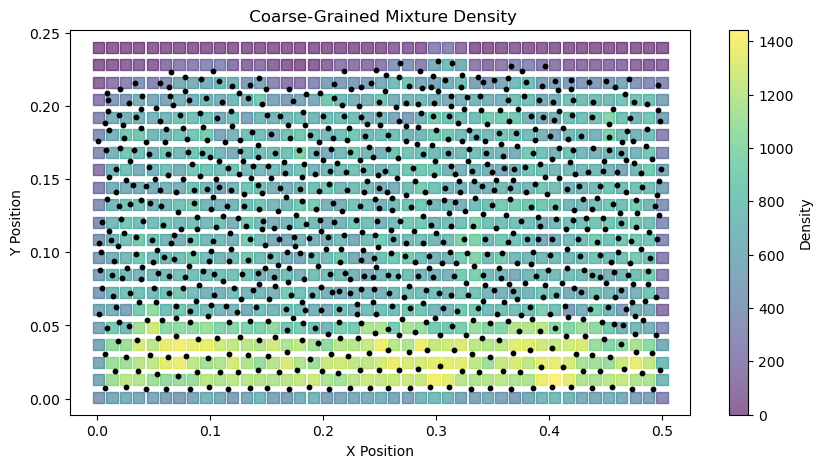

In [27]:
# Create figure and axis
fig = plt.figure(figsize=(10,5))
ax = fig.add_subplot(111)

# Plot DEM particle positions 
bedload_DEM = pv.read('../data_examples/bedload_transport/DEM_data/DES_FB1_0150.vtp')
bedload_particles = bedload_DEM.points
x_particle = bedload_particles[:, 0]; y_particle = bedload_particles[:, 1]
ax.scatter(x_particle, y_particle, s=10, c='k', alpha=1, label='Particle Positions', zorder=3)

# Plot the CG data
x = np.asarray(bedload_CG.positions[:, 0]) 
y = np.asarray(bedload_CG.positions[:, 1])
z = np.asarray(bedload_CG.positions[:, 2])
var = np.asarray(bedload_CG.density_mixture.values[0, :])
sc = ax.scatter(x, y, s=65, c=var, 
                cmap='viridis', alpha=0.6, label='CG Density', 
                zorder=1, marker='s')

# Add colorbar and labels
plt.colorbar(sc, ax=ax, label='Density')
ax.set_xlabel('X Position')
ax.set_ylabel('Y Position')
ax.set_title(' Coarse-Grained Mixture Density')
plt.show()

### 3. Plotting the granular temperature field at a specific time step

The vertical profiles of the coarse-grained fields can be plotted using the following code, which uses the subpackage `vertical_profiles`. Below we plot the profile of density_mixture of the first time step, after performing vertical intergration to obtain vertical profiles.

Starting integration along profile dimension: y
Completed integration along profile dimension: y


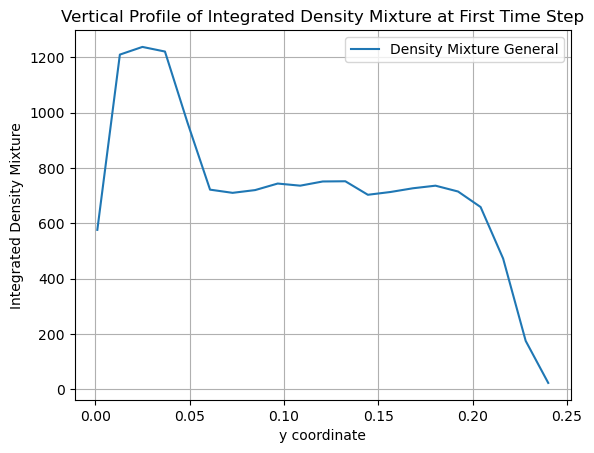

In [28]:
# Perform vertical integration
VI = VerticalIntegrator(bedload_CG, 'y')
vertical_ds_general = VI.integration()

# plot the profile of density_mixture of the first time step
vertical_ds_general['density_mixture'].isel(time=0).plot.line(x='y', label='Density Mixture General')
plt.xlabel('y coordinate')
plt.ylabel('Integrated Density Mixture')
plt.title('Vertical Profile of Integrated Density Mixture at First Time Step')
plt.legend()
plt.grid()
plt.show()

### 4. Plotting the granular temperature slices calculated with other methods

Pysammos provides the granular temperature slices along specified transects using other methods. See the documentation for more details: check the page `gran_temp_slices`.

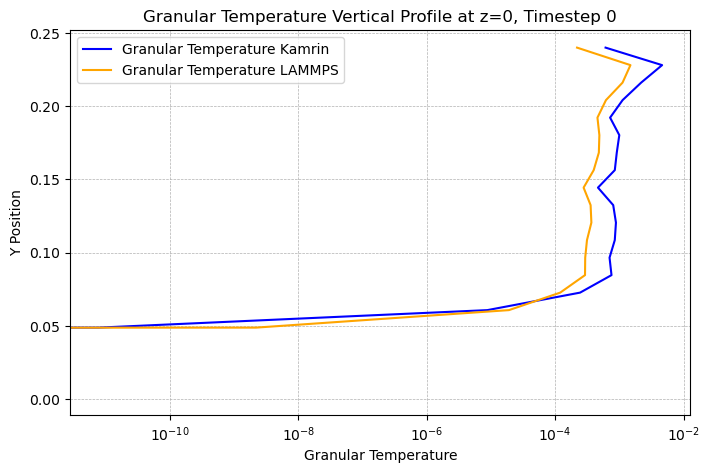

In [29]:
# plot first time step vertical profile comparing Kamrin and LAMMPS
fig, ax = plt.subplots(figsize=(8,5))
ax.plot(slices_gt.granular_temperature_Kamrin[0,:,0], slices_gt.positions[:, 1], label='Granular Temperature Kamrin', color='blue')
ax.plot(slices_gt.granular_temperature_LAMMPS[0,:,0], slices_gt.positions[:, 1], label='Granular Temperature LAMMPS', color='orange')
ax.set_xlabel('Granular Temperature')
ax.set_ylabel('Y Position')
ax.set_title('Granular Temperature Vertical Profile at z=0, Timestep 0')
#gridlines
ax.grid(visible=True, which='both', linestyle='--', linewidth=0.5)
# log scale x axis
ax.set_xscale('log')
ax.legend()
plt.show()  

### 5. Plotting time-averaged data

Pysammos also calculates time-averaged quantities, below we show how to visualise them:

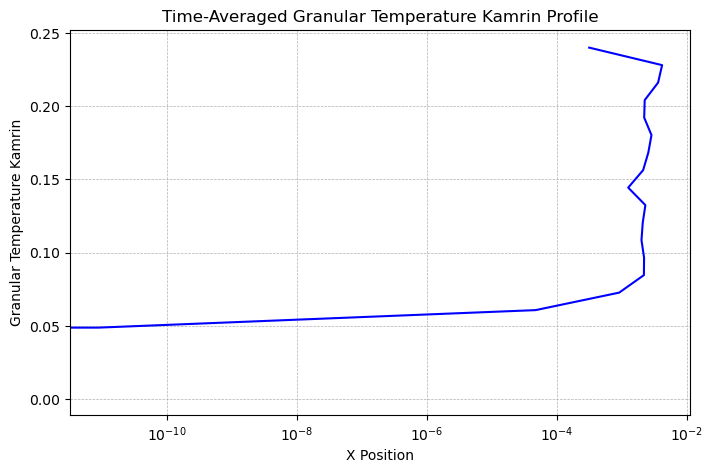

In [31]:
fig, ax = plt.subplots(figsize=(8,5))
ax.plot(slices_gt_avg.granular_temperature_Kamrin[0,:,0], slices_gt_avg.positions[:, 1], color="blue")
ax.set_xlabel('X Position')
ax.set_ylabel('Granular Temperature Kamrin')
ax.set_title('Time-Averaged Granular Temperature Kamrin Profile')
ax.grid(visible=True, which='both', linestyle='--', linewidth=0.5)
ax.set_xscale('log')
plt.show()

Note that time averaging of non-linear fields, e.g. inertial number, is constructred from the time-averaged quantities, instead of taking the time series average of the non-linear field of interest. The difference between these two calculations is shown below: 

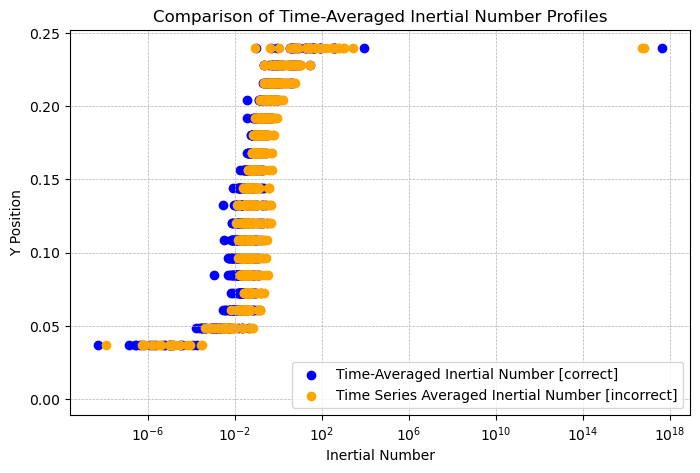

In [36]:
# Calculate time-averaged and time series averaged inertial numbers
I_tav = bedload_CG_avg.inertial_number_Sxy_Pxy_d32[0,:]
I_ts_averaged = bedload_CG.inertial_number_Sxy_Pxy_d32.mean(dim='time')

# plot difference between time-averaged inertial number and time series averaged inertial number
fig, ax = plt.subplots(figsize=(8,5))
ax.scatter(I_tav, bedload_CG_avg.positions[:, 1], label='Time-Averaged Inertial Number [correct]', color='blue')
ax.scatter(I_ts_averaged,  bedload_CG_avg.positions[:, 1], label='Time Series Averaged Inertial Number [incorrect]', color='orange')
ax.set_xlabel('Inertial Number')
ax.set_ylabel('Y Position')
ax.set_title('Comparison of Time-Averaged Inertial Number Profiles')
#gridlines
ax.grid(visible=True, which='both', linestyle='--', linewidth=0.5)
# log scale x axis
ax.set_xscale('log')
plt.legend(loc='lower right')
plt.show()